c:\Users\ADMIN\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\ADMIN\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


--- KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH (TRÊN BỘ 303 GỐC) ---
Accuracy (Tập Test)  : 90.16%
Precision (Độ tin cậy): 84.38%
Recall (Độ nhạy y khoa): 96.43%
ROC-AUC Score        : 96.00%
10-Fold CV Trung bình: 81.85% (Cao nhất đạt: 93.33%)


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_11608\1226076752.py:104: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Weight', y='Feature', data=weights, palette=colors, ax=axes[2])


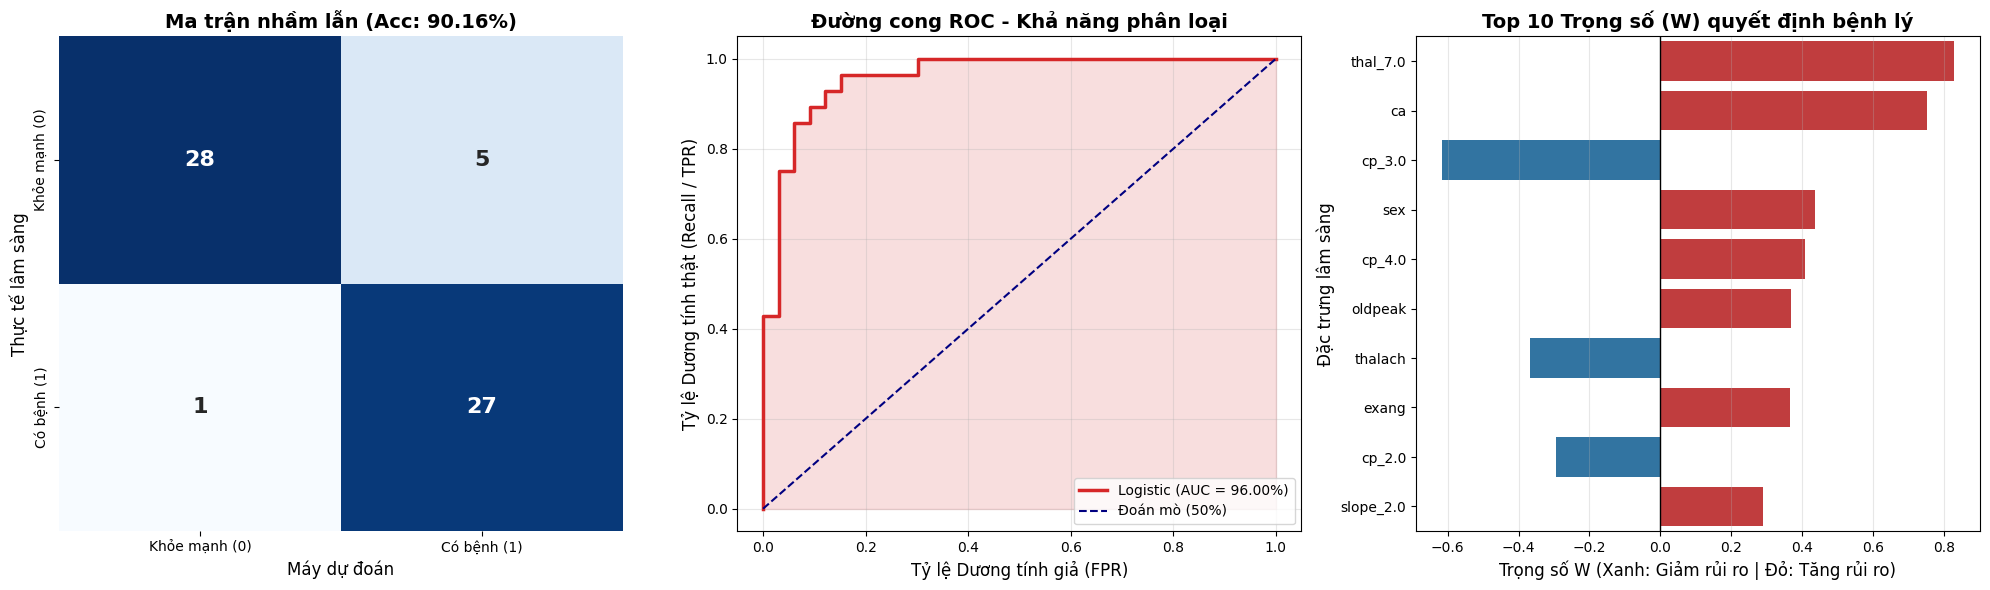

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import KNNImputer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score, confusion_matrix, roc_curve

# ==========================================
# BƯỚC 1: ĐỌC VÀ LÀM SẠCH DỮ LIỆU GỐC 303 DÒNG
# ==========================================
df = pd.read_excel("Book1.xlsx")

# Gán tên cột chuẩn y khoa do file gốc không có Header
df.columns = ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']

# Bản gốc có 5 nhãn (0-4), quy về nhị phân: 0 (Khỏe mạnh) và >0 (Có bệnh)
df['target'] = (df['target'] > 0).astype(int)

# Bản gốc dùng '?' để đánh dấu dữ liệu khuyết, chuyển về định dạng NaN của Numpy
df.replace('?', np.nan, inplace=True)
df_clean = df.drop_duplicates().copy()

# Nội suy KNN cứu 6 ca khuyết (n_neighbors=5)
imputer = KNNImputer(n_neighbors=5)
df_imputed = pd.DataFrame(imputer.fit_transform(df_clean), columns=df_clean.columns)
df_imputed['ca'] = df_imputed['ca'].round()
df_imputed['thal'] = df_imputed['thal'].round()

# ==========================================
# BƯỚC 2: TẠO CHỈ SỐ Y KHOA RPP & MÃ HÓA
# ==========================================
df_imputed['RPP'] = df_imputed['trestbps'] * df_imputed['thalach']
categorical_cols = ['cp', 'restecg', 'slope', 'thal']
df_encoded = pd.get_dummies(df_imputed, columns=categorical_cols, drop_first=True)

# Chuẩn hóa Z-Score (StandardScaler)
continuous_cols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'RPP']
scaler = StandardScaler()
df_encoded[continuous_cols] = scaler.fit_transform(df_encoded[continuous_cols])

# ==========================================
# BƯỚC 3: CHIA TẬP PHÂN TẦNG (STRATIFIED SPLIT)
# ==========================================
X = df_encoded.drop('target', axis=1)
y = df_encoded['target']

# Chia 80/20, giữ nguyên tỷ lệ bệnh nhân ở cả 2 tập
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# ==========================================
# BƯỚC 4: HUẤN LUYỆN LOGISTIC REGRESSION TỐI ƯU
# ==========================================
best_lr = LogisticRegression(C=0.2, penalty='l2', solver='liblinear', max_iter=1000)
best_lr.fit(X_train, y_train)

y_pred = best_lr.predict(X_test)
y_prob = best_lr.predict_proba(X_test)[:, 1]

skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
cv_scores = cross_val_score(best_lr, X, y, cv=skf, scoring='accuracy')

print(f"--- KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH (TRÊN BỘ 303 GỐC) ---")
print(f"Accuracy (Tập Test)  : {accuracy_score(y_test, y_pred)*100:.2f}%")
print(f"Precision (Độ tin cậy): {precision_score(y_test, y_pred)*100:.2f}%")
print(f"Recall (Độ nhạy y khoa): {recall_score(y_test, y_pred)*100:.2f}%")
print(f"ROC-AUC Score        : {roc_auc_score(y_test, y_prob)*100:.2f}%")
print(f"10-Fold CV Trung bình: {cv_scores.mean()*100:.2f}% (Cao nhất đạt: {cv_scores.max()*100:.2f}%)")

# ==========================================
# BƯỚC 5: VẼ BỘ 3 ĐỒ THỊ BÁO CÁO HỘI ĐỒNG
# ==========================================
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# Đồ thị 1: Ma trận nhầm lẫn
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0], annot_kws={"size": 16, "weight": "bold"}, cbar=False)
axes[0].set_title(f'Ma trận nhầm lẫn (Acc: {accuracy_score(y_test, y_pred)*100:.2f}%)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Máy dự đoán', fontsize=12)
axes[0].set_ylabel('Thực tế lâm sàng', fontsize=12)
axes[0].set_xticklabels(['Khỏe mạnh (0)', 'Có bệnh (1)'])
axes[0].set_yticklabels(['Khỏe mạnh (0)', 'Có bệnh (1)'])

# Đồ thị 2: Đường cong ROC-AUC
fpr, tpr, _ = roc_curve(y_test, y_prob)
axes[1].plot(fpr, tpr, color='#d62728', lw=2.5, label=f'Logistic (AUC = {roc_auc_score(y_test, y_prob)*100:.2f}%)')
axes[1].plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle='--', label='Đoán mò (50%)')
axes[1].fill_between(fpr, tpr, alpha=0.15, color='#d62728')
axes[1].set_title('Đường cong ROC - Khả năng phân loại', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Tỷ lệ Dương tính giả (FPR)', fontsize=12)
axes[1].set_ylabel('Tỷ lệ Dương tính thật (Recall / TPR)', fontsize=12)
axes[1].legend(loc="lower right")
axes[1].grid(alpha=0.3)

# Đồ thị 3: Giải thích AI (Explainable AI - Trọng số W)
weights = pd.DataFrame({'Feature': X.columns, 'Weight': best_lr.coef_[0]})
weights = weights.sort_values(by='Weight', key=abs, ascending=False).head(10)
colors = ['#d62728' if x > 0 else '#1f77b4' for x in weights['Weight']]

sns.barplot(x='Weight', y='Feature', data=weights, palette=colors, ax=axes[2])
axes[2].set_title('Top 10 Trọng số (W) quyết định bệnh lý', fontsize=14, fontweight='bold')
axes[2].set_xlabel('Trọng số W (Xanh: Giảm rủi ro | Đỏ: Tăng rủi ro)', fontsize=12)
axes[2].set_ylabel('Đặc trưng lâm sàng', fontsize=12)
axes[2].axvline(0, color='black', linewidth=1)
axes[2].grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()